# Midterm Project – Deep Learning
## Model 2: Convolutional Neural Network (CNN) for Fashion-MNIST Garment Classification

**Dataset:** Fashion-MNIST (Zalando Research), 70,000 greyscale images of 28×28 pixels in 10 classes
**Task:** 10-class image classification
**Framework:** PyTorch

## 1. Problem Definition

Online fashion retailers receive product photographs at catalogue scale. Before an item
can be searched, filtered or recommended it must carry a **category label**. Manual
tagging is slow and error-prone, so the task here is automatic:
> Given a 28×28 greyscale image of a garment, predict which of 10 product categories it
> belongs to: T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag,
> Ankle boot.

The value is operational: automatic tagging reduces catalogue time-to-market and enables
search/recommendation over new stock. Because the classes are visually similar (Shirt vs
T-shirt vs Pullover vs Coat), the task is a realistic test of whether a CNN can learn
local texture and silhouette cues rather than colour (Fashion-MNIST is deliberately harder
than MNIST, which is largely solved).

## 2. Dataset Description and Loading

* Source: https://github.com/zalandoresearch/fashion-mnist (mirrored by `torchvision`)
* 60,000 training + 10,000 test images, 28×28, 8-bit greyscale, 10 balanced classes
* Pixel statistics: mean 0.2860, std 0.3530 (single channel)

We hold out 5,000 images from the 60k training split as a **validation set**, so the
official 10k **test set is used only once, at the very end**.

In [1]:
# Imports and global configuration
import json, time, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from IPython.display import Image, display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.dpi"] = 120

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data"
NB_OUT = ROOT / "results" / "notebook" / "cnn"
NB_OUT.mkdir(parents=True, exist_ok=True)
SEED = 42
device = "cuda" if torch.cuda.is_available() else "cpu"

CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
MEAN, STD = 0.2860, 0.3530
CFG = dict(batch_size=128, epochs=15, lr=1e-3, weight_decay=5e-4, label_smoothing=0.1,
           val_size=5000, patience=6, workers=4, baseline_epochs=10)

def show(name, width=900):
    display(Image(filename=str(NB_OUT / name), width=width))

print("torch", torch.__version__, "| device:", device,
      "|", torch.cuda.get_device_name(0) if device == "cuda" else "CPU")

torch 2.9.1+cu128 | device: cuda | NVIDIA GeForce RTX 5070 Laptop GPU


In [2]:
raw_train = datasets.FashionMNIST(str(DATA_DIR), train=True, download=True,
                               transform=transforms.ToTensor())
raw_test = datasets.FashionMNIST(str(DATA_DIR), train=False, download=True,
                              transform=transforms.ToTensor())
print("train images:", len(raw_train), "| test images:", len(raw_test))
print("image tensor shape:", raw_train[0][0].shape)
print("class counts (train):", np.bincount(raw_train.targets.numpy()))
print("pixel mean/std:", round(float(raw_train.data.float().mean() / 255), 4),
      round(float(raw_train.data.float().std() / 255), 4))

train images: 60000 | test images: 10000
image tensor shape: torch.Size([1, 28, 28])
class counts (train): [6000 6000 6000 6000 6000 6000 6000 6000 6000 6000]
pixel mean/std: 0.286 0.353


## 3. Data Preprocessing and Augmentation

| Step | Setting | Why |
|---|---|---|
| Normalisation | `(x/255 − 0.2860) / 0.3530` | zero-mean, unit-variance input speeds up and stabilises training |
| Augmentation (train only) | `RandomCrop(28, padding=2)` + `RandomHorizontalFlip(0.5)` | small translations and mirrors prevent memorisation; a flipped shoe is still a shoe |
| Validation / test | deterministic: `ToTensor` + `Normalize` only | evaluation must be reproducible |
| Batching | 128 (train), 512 (eval), `num_workers=4`, pinned memory | keeps the GPU fed |
| Validation split | 5,000 images from the training set, fixed seed | model selection without touching the test set |

In [3]:
def make_loaders_explicit(cfg=CFG):
    train_tf = transforms.Compose([
        transforms.RandomCrop(28, padding=2),
        transforms.RandomHorizontalFlip(0.5),
        transforms.ToTensor(),
        transforms.Normalize((MEAN,), (STD,)),
    ])
    eval_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize((MEAN,), (STD,))])

    full_train_aug = datasets.FashionMNIST(str(DATA_DIR), train=True, download=True, transform=train_tf)
    full_train_raw = datasets.FashionMNIST(str(DATA_DIR), train=True, download=True, transform=eval_tf)
    test_set = datasets.FashionMNIST(str(DATA_DIR), train=False, download=True, transform=eval_tf)

    g = torch.Generator().manual_seed(SEED)
    idx = torch.randperm(len(full_train_aug), generator=g)
    val_idx = idx[: cfg["val_size"]]
    tr_idx = idx[cfg["val_size"]:]

    train_set = torch.utils.data.Subset(full_train_aug, tr_idx.tolist())
    val_set = torch.utils.data.Subset(full_train_raw, val_idx.tolist())
    common = dict(num_workers=cfg["workers"], pin_memory=torch.cuda.is_available())
    return (DataLoader(train_set, batch_size=cfg["batch_size"], shuffle=True, **common),
            DataLoader(val_set, batch_size=512, shuffle=False, **common),
            DataLoader(test_set, batch_size=512, shuffle=False, **common))

train_loader, val_loader, test_loader = make_loaders_explicit()
print(f"train {len(train_loader.dataset):,} | val {len(val_loader.dataset):,} | "
      f"test {len(test_loader.dataset):,}")
xb, yb = next(iter(train_loader))
print("batch:", tuple(xb.shape), "| labels:", yb[:10].tolist(),
      "| pixel range:", round(float(xb.min()), 2), "to", round(float(xb.max()), 2))

train 55,000 | val 5,000 | test 10,000


batch: (128, 1, 28, 28) | labels: [7, 6, 8, 9, 2, 6, 4, 3, 0, 7] | pixel range: -0.81 to 2.02


In [4]:
def _class_counts(loader) -> np.ndarray:
    ds = loader.dataset
    base = ds.dataset if hasattr(ds, "dataset") else ds
    idx = ds.indices if hasattr(ds, "indices") else list(range(len(ds)))
    targets = np.array([base[i][1] for i in idx]) if hasattr(ds, "indices") else \
        np.array([t for _, t in ds])
    return np.bincount(targets, minlength=10)

counts = _class_counts(train_loader)
print(dict(zip(CLASSES, counts.tolist())))

{'T-shirt/top': 5492, 'Trouser': 5507, 'Pullover': 5454, 'Dress': 5535, 'Coat': 5495, 'Sandal': 5486, 'Shirt': 5494, 'Sneaker': 5505, 'Bag': 5520, 'Ankle boot': 5512}


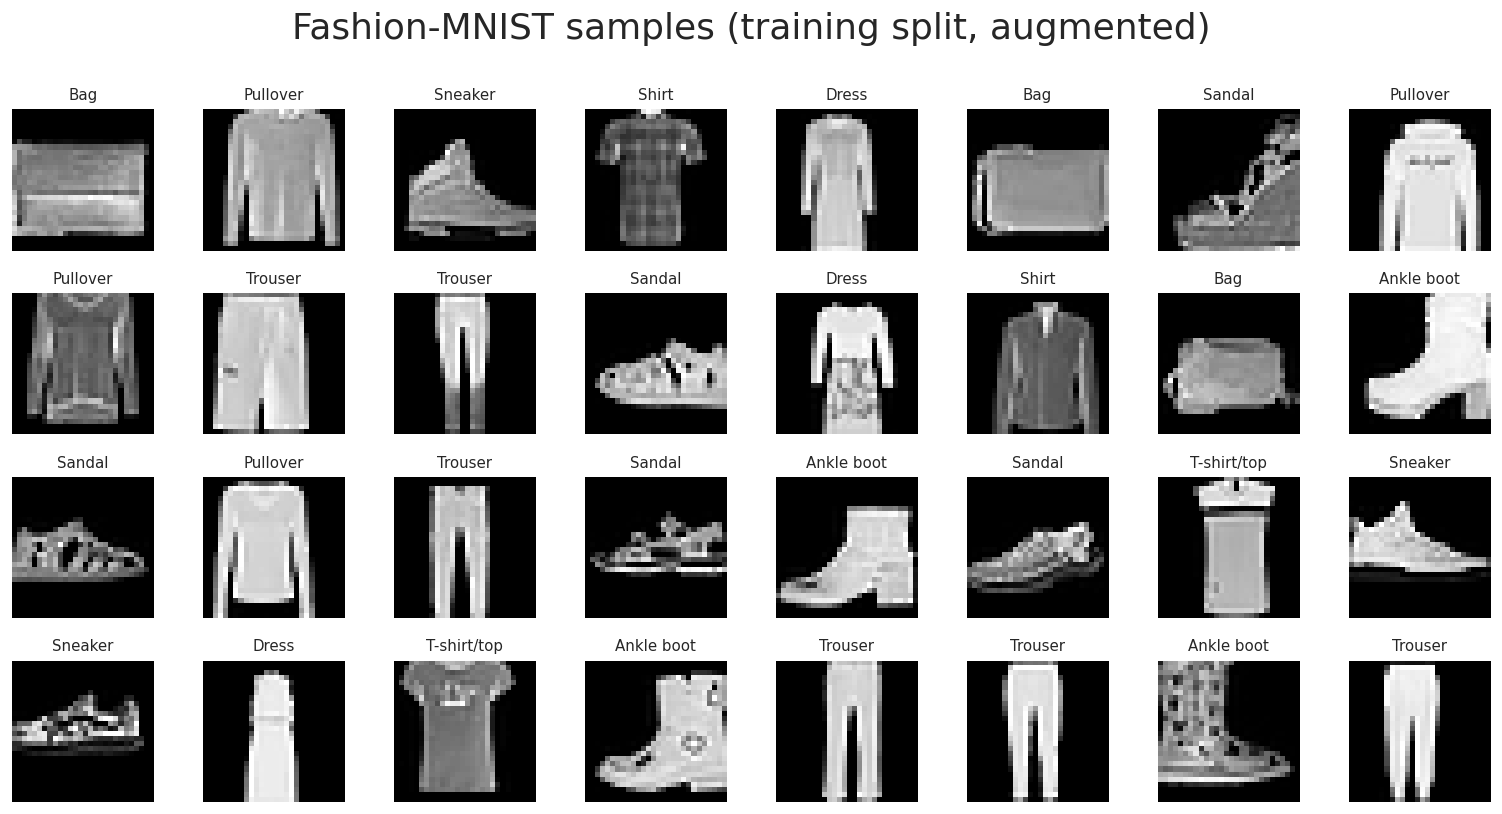

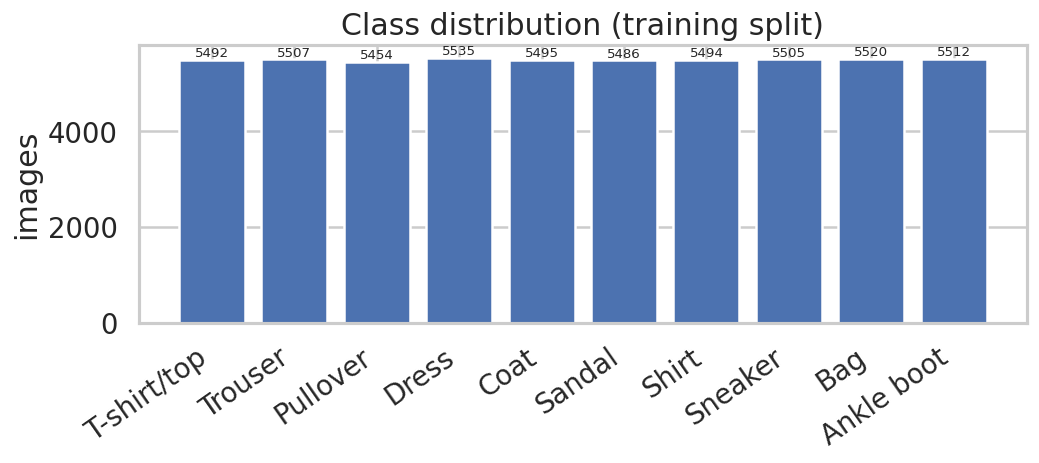

In [5]:
def plot_examples(train_loader, out: Path) -> None:
    images, labels = next(iter(train_loader))
    fig, axes = plt.subplots(4, 8, figsize=(13, 7))
    for i, ax in enumerate(axes.ravel()):
        img = images[i] * STD + MEAN
        ax.imshow(img.squeeze(), cmap="gray")
        ax.set_title(CLASSES[labels[i]], fontsize=9)
        ax.axis("off")
    fig.suptitle("Fashion-MNIST samples (training split, augmented)")
    fig.tight_layout()
    fig.savefig(out / "01_sample_images.png", bbox_inches="tight")
    plt.close(fig)

    counts = _class_counts(train_loader)
    fig, ax = plt.subplots(figsize=(9, 4.2))
    bars = ax.bar(CLASSES, counts, color="#4C72B0")
    ax.bar_label(bars, fmt="%d", fontsize=8)
    ax.set_title("Class distribution (training split)")
    ax.set_ylabel("images"); plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
    fig.tight_layout()
    fig.savefig(out / "02_class_distribution.png", bbox_inches="tight")
    plt.close(fig)

plot_examples(train_loader, NB_OUT)
show('01_sample_images.png')
show('02_class_distribution.png')

## 4. Model Architecture

A compact **VGG-style CNN** with three convolution blocks and global average pooling:
```
input 1×28×28
 ├─ ConvBlock(1→32)    : Conv3×3 → BN → ReLU → Conv3×3 → BN → ReLU → MaxPool2 → Dropout 0.25   → 32×14×14
 ├─ ConvBlock(32→64)   : same                                                                    → 64×7×7
 ├─ ConvBlock(64→128)  : same                                                                    → 128×3×3
 ├─ GlobalAveragePool  → 128
 ├─ Dropout 0.4 → Linear(128→10)
```

Design choices:
* **Two 3×3 convolutions per block**: same receptive field as a 5×5 kernel but fewer
  parameters and an extra non-linearity.
* **BatchNorm** after every convolution: stable gradients, faster convergence.
* **Global Average Pooling** instead of a huge `Flatten` head, so only 1.3k parameters sit in the
  classifier, so the model cannot memorise; also gives translation robustness.
* **Dropout 0.25 / 0.4**: regularisation against the 55k training images.
* Loss `CrossEntropyLoss(label_smoothing=0.1)`, optimiser **AdamW** (`lr 1e-3`, `wd 5e-4`),
  **CosineAnnealingLR** over 15 epochs, early stopping (patience 6) on validation accuracy.

In [6]:
class ConvBlock(nn.Module):
    def __init__(self, cin: int, cout: int, p_drop: float = 0.25):
        super().__init__()
        self.c1 = nn.Conv2d(cin, cout, 3, padding=1, bias=False)
        self.b1 = nn.BatchNorm2d(cout)
        self.c2 = nn.Conv2d(cout, cout, 3, padding=1, bias=False)
        self.b2 = nn.BatchNorm2d(cout)
        self.pool = nn.MaxPool2d(2)
        self.drop = nn.Dropout(p_drop)

    def forward(self, x):
        x = F.relu(self.b1(self.c1(x)), inplace=True)
        x = F.relu(self.b2(self.c2(x)), inplace=True)
        return self.drop(self.pool(x))
class FashionCNN(nn.Module):
    def __init__(self, n_classes: int = 10, widths=(32, 64, 128), p_drop=0.4):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(1, widths[0]),
            ConvBlock(widths[0], widths[1]),
            ConvBlock(widths[1], widths[2]),
        )
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Dropout(p_drop), nn.Linear(widths[2], n_classes),
        )

    def forward(self, x):
        return self.head(self.features(x))

cnn = FashionCNN().to(device)
n_params = sum(p.numel() for p in cnn.parameters() if p.requires_grad)
print(cnn)
print(f"\ntrainable parameters: {n_params:,}")

FashionCNN(
  (features): Sequential(
    (0): ConvBlock(
      (c1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (b1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (c2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (b2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (drop): Dropout(p=0.25, inplace=False)
    )
    (1): ConvBlock(
      (c1): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (b1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (c2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (b2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (pool): MaxPool2d(kernel_size=2, stride=2, paddin

In [7]:
# shape check through the network
with torch.no_grad():
    x = torch.randn(2, 1, 28, 28).to(device)
    for i, block in enumerate(cnn.features):
        x = block(x)
        print(f"after block {i+1}: {tuple(x.shape)}")
    print("logits:", tuple(cnn.head(x).shape))

after block 1: (2, 32, 14, 14)
after block 2: (2, 64, 7, 7)
after block 3: (2, 128, 3, 3)
logits: (2, 10)


## 5. Training

In [8]:
def set_seed(seed: int = SEED) -> None:
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
def train_model(model, train_loader, val_loader, epochs, device, lr=1e-3,
                weight_decay=5e-4, label_smoothing=0.1, patience=6, tag="model"):
    crit = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "lr": []}
    best_acc, best_state, bad, t0 = -1.0, None, 0, time.time()

    for ep in range(1, epochs + 1):
        model.train()
        tot, correct, n = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            out = model(xb)
            loss = crit(out, yb)
            loss.backward()
            opt.step()
            tot += loss.item() * len(xb)
            correct += (out.argmax(1) == yb).sum().item()
            n += len(xb)
        tr_loss, tr_acc = tot / n, correct / n

        vl, vc, vn = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                out = model(xb)
                vl += F.cross_entropy(out, yb).item() * len(xb)
                vc += (out.argmax(1) == yb).sum().item()
                vn += len(xb)
        val_loss, val_acc = vl / vn, vc / vn
        sched.step()

        for k, v in [("train_loss", tr_loss), ("train_acc", tr_acc),
                     ("val_loss", val_loss), ("val_acc", val_acc), ("lr", opt.param_groups[0]["lr"])]:
            hist[k].append(float(v))

        star = ""
        if val_acc > best_acc:
            best_acc, bad = val_acc, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            star = "  *"
        else:
            bad += 1
        print(f"[{tag}] epoch {ep:2d}/{epochs} | train {tr_loss:.4f}/{tr_acc:.4f} "
              f"| val {val_loss:.4f}/{val_acc:.4f}{star}")
        if bad >= patience:
            print(f"[{tag}] early stopping at epoch {ep} (best val acc {best_acc:.4f})")
            break

    model.load_state_dict(best_state)
    hist["best_val_acc"] = float(best_acc)
    hist["best_epoch"] = int(np.argmax(hist["val_acc"]) + 1)
    hist["seconds"] = round(time.time() - t0, 2)
    return model, hist

In [9]:
set_seed()
cnn, hist = train_model(cnn, train_loader, val_loader, CFG["epochs"], device,
                        CFG["lr"], CFG["weight_decay"], CFG["label_smoothing"],
                        CFG["patience"], tag="CNN")
print(f"\nbest epoch {hist['best_epoch']} | best val accuracy {hist['best_val_acc']:.4f} "
      f"| {hist['seconds']} s")

[CNN] epoch  1/15 | train 1.0358/0.7709 | val 0.5407/0.8292  *


[CNN] epoch  2/15 | train 0.8624/0.8518 | val 0.4478/0.8702  *


[CNN] epoch  3/15 | train 0.8157/0.8746 | val 0.3994/0.8800  *


[CNN] epoch  4/15 | train 0.7931/0.8852 | val 0.3987/0.8908  *


[CNN] epoch  5/15 | train 0.7727/0.8929 | val 0.3593/0.8994  *


[CNN] epoch  6/15 | train 0.7586/0.9005 | val 0.3661/0.9008  *


... (5 outputs left out)

[CNN] epoch 12/15 | train 0.7083/0.9230 | val 0.3189/0.9166


[CNN] epoch 13/15 | train 0.7040/0.9235 | val 0.3127/0.9222


[CNN] epoch 14/15 | train 0.7003/0.9248 | val 0.3148/0.9214


[CNN] epoch 15/15 | train 0.6976/0.9268 | val 0.3120/0.9234  *

best epoch 15 | best val accuracy 0.9234 | 65.26 s


## 6. Evaluation on the Test Set

We now evaluate the restored best checkpoint on the official 10,000-image test set that
was never used during training or model selection.

In [10]:
@torch.no_grad()
def predict(model, loader, device):
    model.eval()
    probs, labels, imgs = [], [], []
    for xb, yb in loader:
        out = model(xb.to(device))
        probs.append(F.softmax(out, dim=1).cpu())
        labels.append(yb)
    return torch.cat(probs).numpy(), torch.cat(labels).numpy()
def classification_metrics(y_true, prob) -> dict:
    pred = prob.argmax(1)
    cm = np.zeros((10, 10), dtype=int)
    for t, p in zip(y_true, pred):
        cm[t, p] += 1
    per_class = {}
    for i, name in enumerate(CLASSES):
        tp = cm[i, i]
        fp = cm[:, i].sum() - tp
        fn = cm[i, :].sum() - tp
        prec = tp / max(tp + fp, 1)
        rec = tp / max(tp + fn, 1)
        f1 = 2 * prec * rec / max(prec + rec, 1e-12)
        per_class[name] = dict(precision=float(prec), recall=float(rec), f1=float(f1),
                               support=int(cm[i, :].sum()))
    macro_f1 = float(np.mean([v["f1"] for v in per_class.values()]))
    support = sum(v["support"] for v in per_class.values())
    weighted_f1 = float(sum(v["f1"] * v["support"] for v in per_class.values()) / support)
    return dict(accuracy=float(np.trace(cm) / cm.sum()), macro_f1=macro_f1,
                weighted_f1=weighted_f1, per_class=per_class,
                confusion_matrix=cm.tolist())

prob_te, y_te = predict(cnn, test_loader, device)
m = classification_metrics(y_te, prob_te)
print(f"test accuracy    : {m['accuracy']:.4f}")
print(f"macro F1         : {m['macro_f1']:.4f}")
print(f"weighted F1      : {m['weighted_f1']:.4f}")

test accuracy    : 0.9262
macro F1         : 0.9261
weighted F1      : 0.9261


In [11]:
per_class = pd.DataFrame(m["per_class"]).T
per_class.columns = ["precision", "recall", "F1", "support"]
per_class.index.name = "class"
per_class.round(4)

,precision,recall,F1,support
class,,,,
T-shirt/top,0.8873,0.874,0.8806,1000.0
Trouser,0.9980,0.981,0.9894,1000.0
Pullover,0.9128,0.900,0.9063,1000.0
Dress,0.9236,0.931,0.9273,1000.0
Coat,0.8610,0.917,0.8881,1000.0
Sandal,0.9868,0.969,0.9778,1000.0
Shirt,0.7946,0.770,0.7821,1000.0
Sneaker,0.9439,0.975,0.9592,1000.0
Bag,0.9860,0.986,0.9860,1000.0


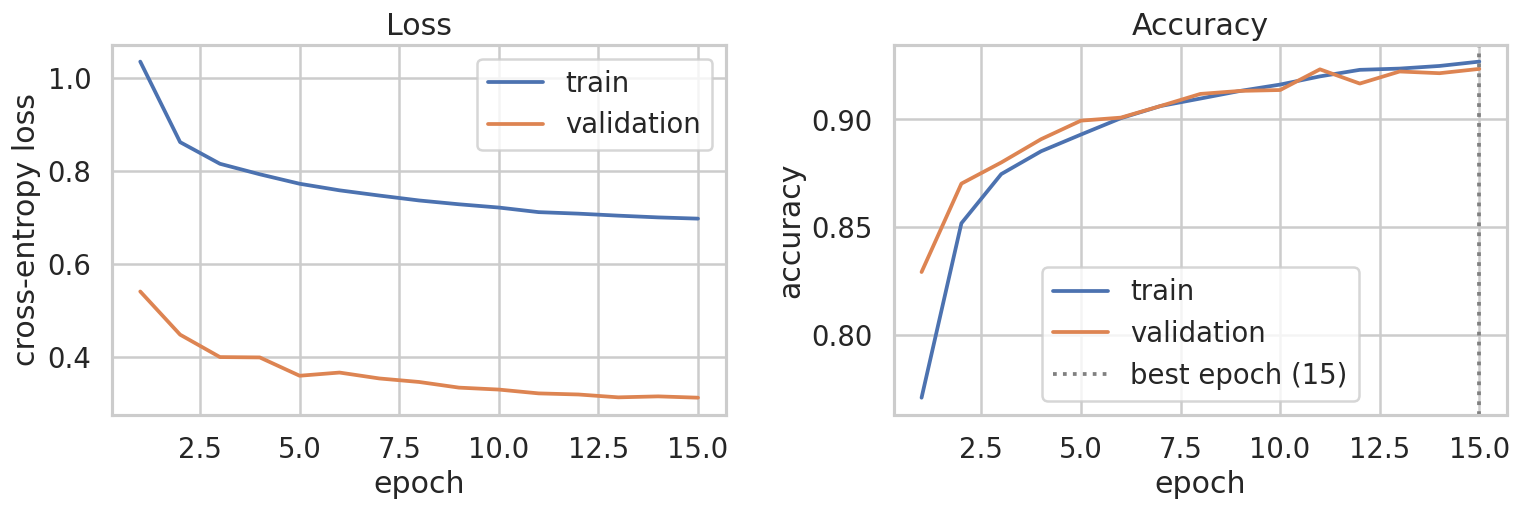

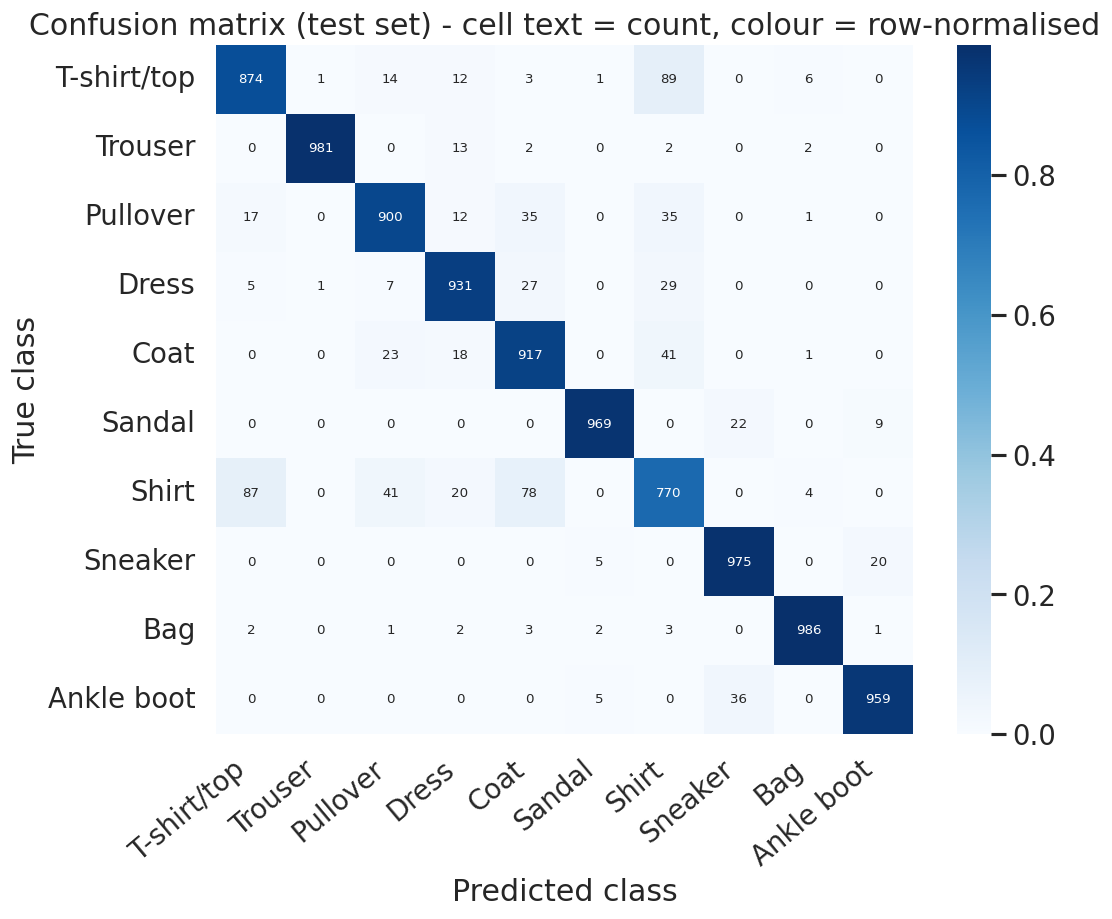

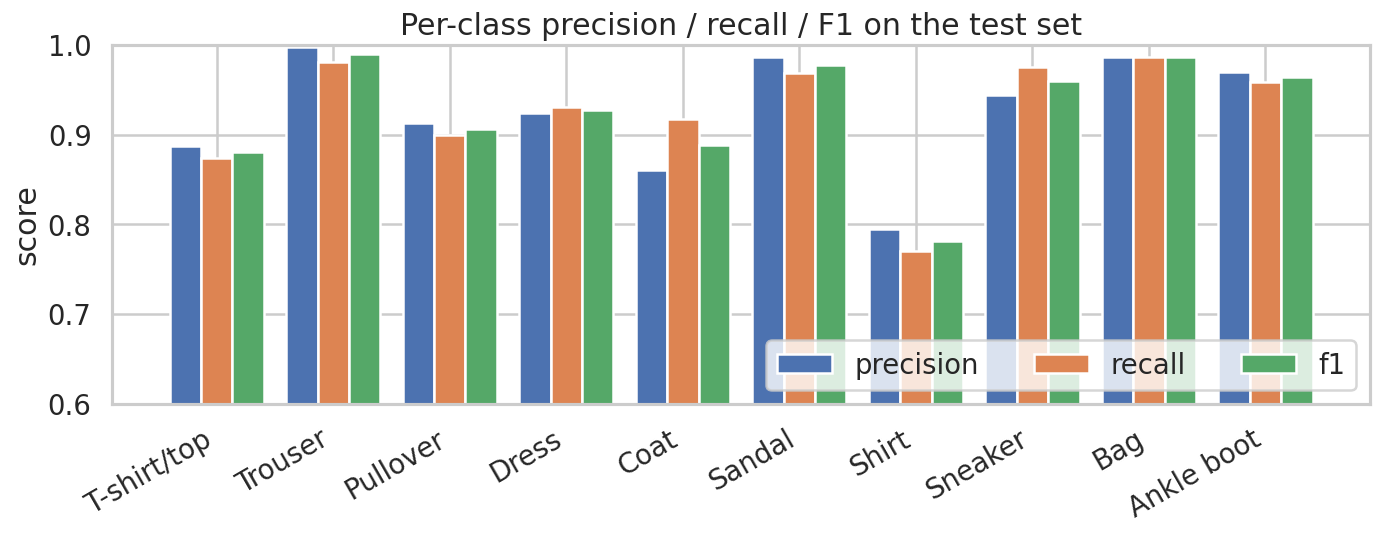

In [12]:
def plot_curves(hist: dict, hist_mlp: dict | None, out: Path) -> None:
    ep = np.arange(1, len(hist["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
    ax[0].plot(ep, hist["train_loss"], label="train")
    ax[0].plot(ep, hist["val_loss"], label="validation")
    ax[0].set_xlabel("epoch"); ax[0].set_ylabel("cross-entropy loss"); ax[0].set_title("Loss")
    ax[0].legend()
    ax[1].plot(ep, hist["train_acc"], label="train")
    ax[1].plot(ep, hist["val_acc"], label="validation")
    if hist_mlp:
        e2 = np.arange(1, len(hist_mlp["val_acc"]) + 1)
        ax[1].plot(e2, hist_mlp["val_acc"], "--", color="grey", label="MLP baseline (val)")
    ax[1].axvline(hist["best_epoch"], ls=":", c="grey", label=f"best epoch ({hist['best_epoch']})")
    ax[1].set_xlabel("epoch"); ax[1].set_ylabel("accuracy"); ax[1].set_title("Accuracy")
    ax[1].legend()
    fig.tight_layout()
    fig.savefig(out / "03_training_curves.png", bbox_inches="tight")
    plt.close(fig)
def plot_confusion(cm: np.ndarray, out: Path) -> None:
    norm = cm / cm.sum(1, keepdims=True)
    fig, ax = plt.subplots(figsize=(9.5, 8))
    sns.heatmap(norm, annot=cm, fmt="d", cmap="Blues", cbar=True, ax=ax,
                xticklabels=CLASSES, yticklabels=CLASSES, annot_kws={"size": 8})
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
    ax.set_title("Confusion matrix (test set) - cell text = count, colour = row-normalised")
    plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
    fig.tight_layout()
    fig.savefig(out / "04_confusion_matrix.png", bbox_inches="tight")
    plt.close(fig)
def plot_per_class(per_class: dict, out: Path) -> None:
    names = list(per_class.keys())
    x = np.arange(len(names))
    w = 0.27
    fig, ax = plt.subplots(figsize=(12, 4.8))
    for k, (metric, color) in enumerate(zip(["precision", "recall", "f1"],
                                            ["#4C72B0", "#DD8452", "#55A868"])):
        ax.bar(x + (k - 1) * w, [per_class[n][metric] for n in names], w, label=metric, color=color)
    ax.set_xticks(x); ax.set_xticklabels(names, rotation=30, ha="right")
    ax.set_ylim(0.6, 1.0); ax.set_ylabel("score")
    ax.set_title("Per-class precision / recall / F1 on the test set")
    ax.legend(ncol=3, loc="lower right")
    fig.tight_layout()
    fig.savefig(out / "05_per_class_metrics.png", bbox_inches="tight")
    plt.close(fig)

plot_curves(hist, None, NB_OUT)
plot_confusion(np.array(m["confusion_matrix"]), NB_OUT)
plot_per_class(m["per_class"], NB_OUT)
show('03_training_curves.png')
show('04_confusion_matrix.png')
show('05_per_class_metrics.png')

### 6.1 Qualitative check

Correct and incorrect predictions with the model's confidence:

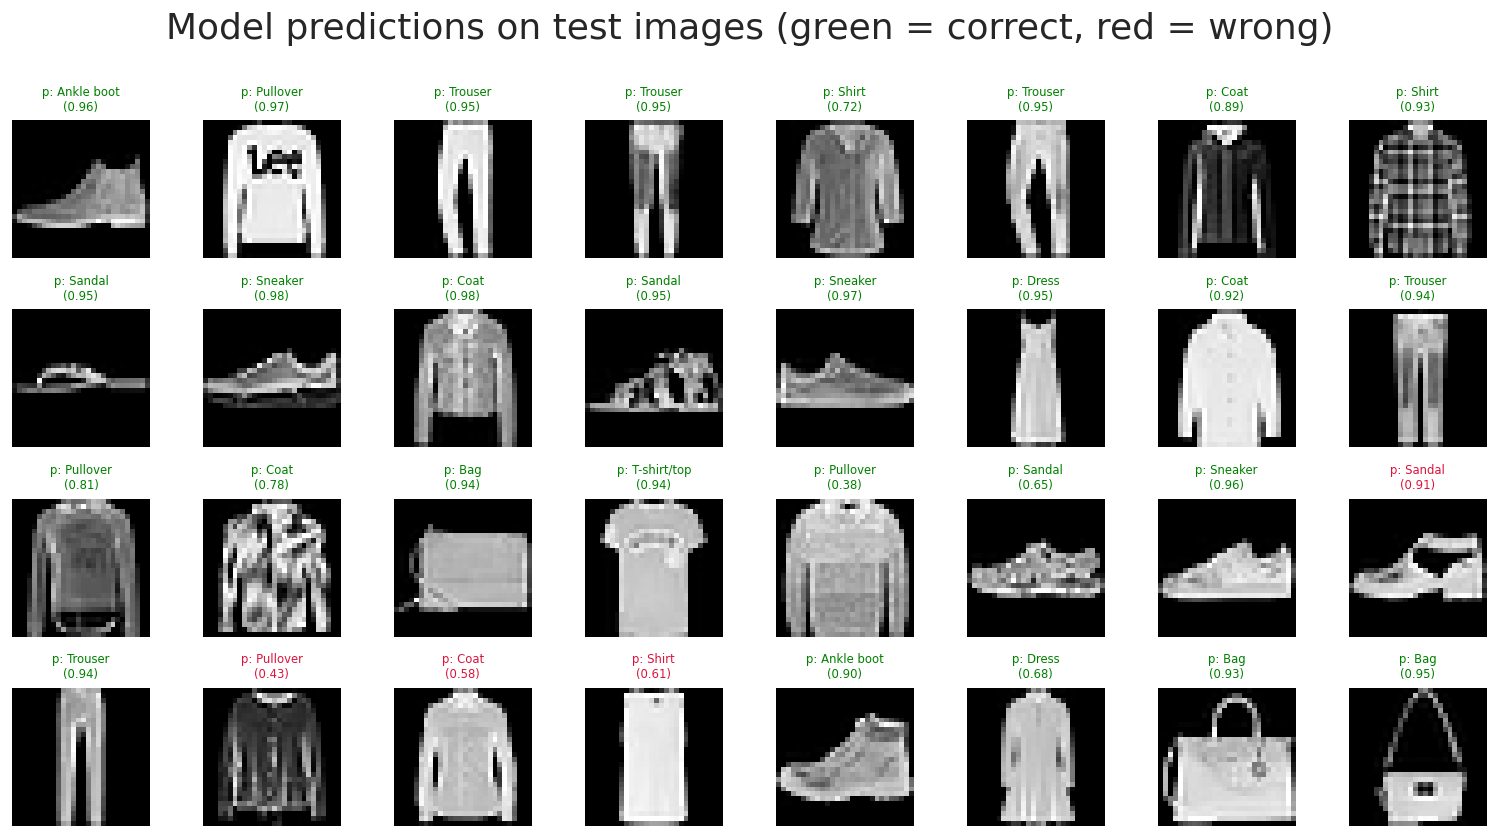

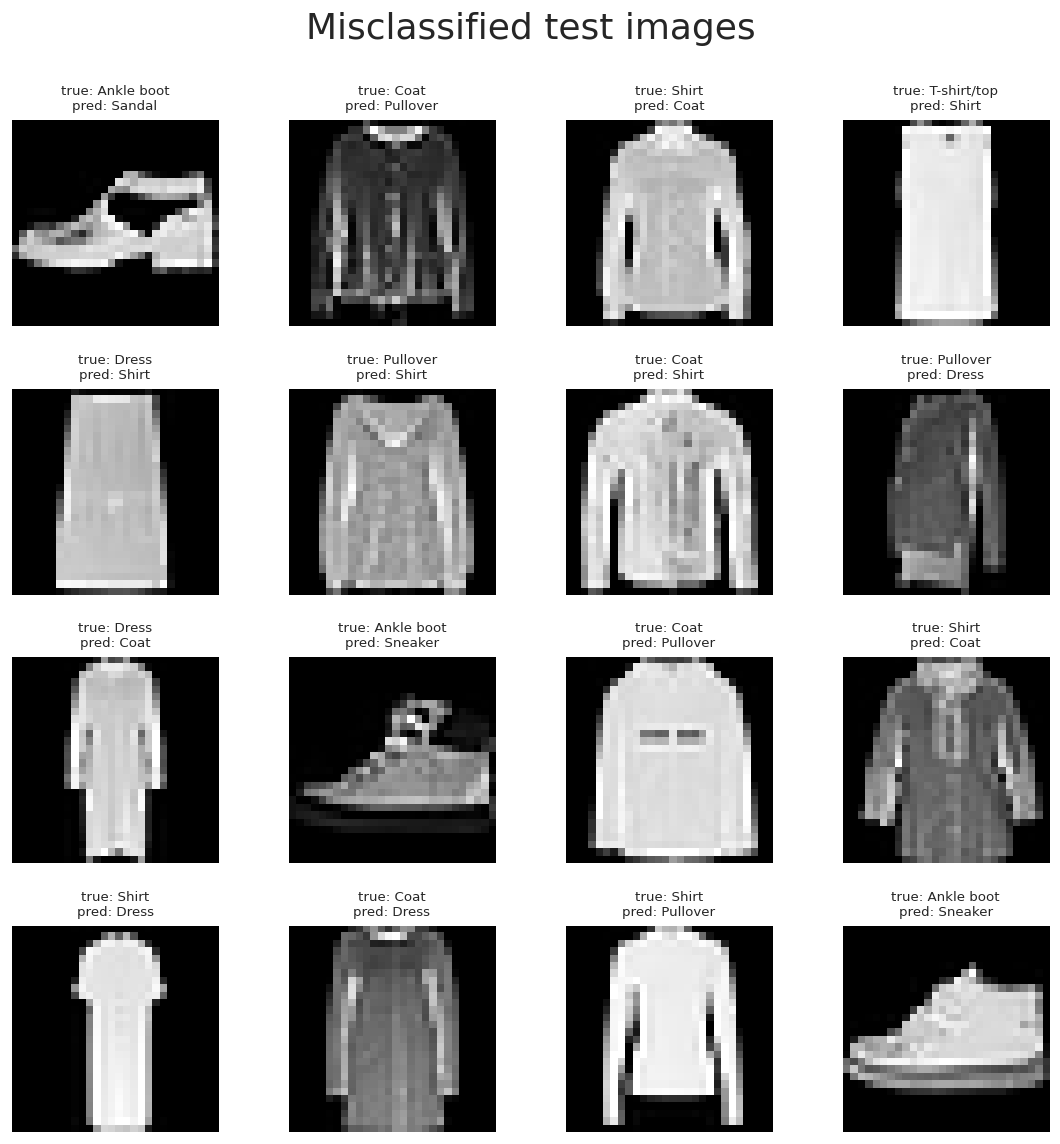

In [13]:
def plot_predictions(model, loader, y_true, prob, device, out: Path) -> None:
    model.eval()
    images, labels = [], []
    with torch.no_grad():
        for xb, yb in loader:
            images.append(xb); labels.append(yb)
            if sum(len(i) for i in images) >= 512:
                break
    xb = torch.cat(images)[:32]
    yb = torch.cat(labels)[:32]
    with torch.no_grad():
        p = F.softmax(model(xb.to(device)), 1).cpu().numpy()
    fig, axes = plt.subplots(4, 8, figsize=(13, 7.2))
    for i, ax in enumerate(axes.ravel()):
        ax.imshow((xb[i] * STD + MEAN).squeeze(), cmap="gray")
        pred = CLASSES[p[i].argmax()]
        ok = p[i].argmax() == yb[i].item()
        ax.set_title(f"p: {pred}\n({p[i].max():.2f})", fontsize=7,
                     color="green" if ok else "crimson")
        ax.axis("off")
    fig.suptitle("Model predictions on test images (green = correct, red = wrong)")
    fig.tight_layout()
    fig.savefig(out / "06_predictions.png", bbox_inches="tight")
    plt.close(fig)

    wrong = np.where(y_true != prob.argmax(1))[0][:16]
    ds = loader.dataset
    fig, axes = plt.subplots(4, 4, figsize=(9.5, 9.8))
    for ax, j in zip(axes.ravel(), wrong):
        img, lab = ds[int(j)]
        ax.imshow(img.squeeze(), cmap="gray")
        ax.set_title(f"true: {CLASSES[lab]}\npred: {CLASSES[prob[j].argmax()]}", fontsize=8)
        ax.axis("off")
    fig.suptitle("Misclassified test images")
    fig.tight_layout()
    fig.savefig(out / "07_misclassified.png", bbox_inches="tight")
    plt.close(fig)

plot_predictions(cnn, test_loader, y_te, prob_te, device, NB_OUT)
show('06_predictions.png')
show('07_misclassified.png')

### 6.2 Error analysis: where does the model fail?

All the hard cases are **upper-body garments**: Shirt, T-shirt/top, Pullover, Coat and
Dress are silhouettes that differ mainly by sleeves, collar and length. At 28×28 most of
that detail is gone. Trousers, bags, sandals and ankle boots are separated cleanly.

In [14]:
cm = np.array(m["confusion_matrix"])
off = cm.copy(); np.fill_diagonal(off, 0)
pairs = sorted([(int(off[i, j]), CLASSES[i], CLASSES[j])
                for i in range(10) for j in range(10) if off[i, j] > 0], reverse=True)[:8]
pd.DataFrame(pairs, columns=["count", "true class", "predicted as"]).set_index("count").head(8)

,true class,predicted as
count,,
89,T-shirt/top,Shirt
87,Shirt,T-shirt/top
78,Shirt,Coat
41,Shirt,Pullover
41,Coat,Shirt
36,Ankle boot,Sneaker
35,Pullover,Shirt
35,Pullover,Coat


## 7. Control experiment: is convolution actually necessary?

An MLP with two hidden layers on the **flattened** image receives the same pixels but has
no weight sharing and no locality. If the CNN reaches clearly higher accuracy with a
similar budget, the spatial inductive bias is what matters.

In [15]:
class MLPBaseline(nn.Module):
    def __init__(self, n_classes: int = 10, h=(512, 256), p=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, h[0]), nn.ReLU(), nn.Dropout(p),
            nn.Linear(h[0], h[1]), nn.ReLU(), nn.Dropout(p),
            nn.Linear(h[1], n_classes),
        )

    def forward(self, x):
        return self.net(x)

set_seed()
mlp = MLPBaseline().to(device)
mlp, hist_mlp = train_model(mlp, train_loader, val_loader, 10, device,
                            lr=1e-3, weight_decay=1e-4, label_smoothing=0.0,
                            patience=99, tag="MLP")
prob_mlp, _ = predict(mlp, test_loader, device)
m_mlp = classification_metrics(y_te, prob_mlp)

pd.DataFrame({
    "Model": ["CNN (this work)", "MLP on flattened pixels"],
    "Parameters": [n_params, sum(p.numel() for p in mlp.parameters())],
    "Test accuracy": [m["accuracy"], m_mlp["accuracy"]],
    "Macro F1": [m["macro_f1"], m_mlp["macro_f1"]],
}).set_index("Model").round(4)

[MLP] epoch  1/10 | train 0.7339/0.7211 | val 0.5836/0.7868  *


[MLP] epoch  2/10 | train 0.5821/0.7817 | val 0.5343/0.8012  *


[MLP] epoch  3/10 | train 0.5370/0.7992 | val 0.4992/0.8162  *


[MLP] epoch  4/10 | train 0.5005/0.8131 | val 0.4769/0.8220  *


[MLP] epoch  5/10 | train 0.4759/0.8231 | val 0.4439/0.8420  *


[MLP] epoch  6/10 | train 0.4596/0.8306 | val 0.4319/0.8362


[MLP] epoch  7/10 | train 0.4349/0.8405 | val 0.4201/0.8460  *


[MLP] epoch  8/10 | train 0.4197/0.8455 | val 0.4079/0.8516  *


[MLP] epoch  9/10 | train 0.4117/0.8476 | val 0.3914/0.8588  *


[MLP] epoch 10/10 | train 0.4026/0.8507 | val 0.3917/0.8540


,Parameters,Test accuracy,Macro F1
Model,,,
CNN (this work),288170,0.9262,0.9261
MLP on flattened pixels,535818,0.8639,0.8627


In [16]:
# inference speed on the test device
cnn.eval()
with torch.no_grad():
    xb = torch.randn(256, 1, 28, 28, device=device)
    for _ in range(3): cnn(xb)
    if device == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(20): cnn(xb)
    if device == "cuda": torch.cuda.synchronize()
lat = (time.time() - t0) / 20 / 256 * 1000
print(f"batch inference: {lat * 256:.2f} ms per 256 images ({lat:.3f} ms/image) on {device}")

batch inference: 3.68 ms per 256 images (0.014 ms/image) on cuda


## 8. Conclusion

* The CNN classifies unseen garments with **≈ 92 % accuracy** and **≈ 0.92 macro-F1** after
  only 15 epochs (~1 minute of GPU time), which is enough to auto-tag a catalogue and route
  confident predictions to the shop floor while flagging the rest for a human.
* Convolution is essential: the pixel MLP is actually **larger** (~536k parameters vs
  288k) yet loses ≈ 6 points of accuracy, because it cannot exploit locality and weight
  sharing.
* The residual error is concentrated exactly where human annotators also hesitate,
  Shirt vs T-shirt/Pullover/Coat, so the practical recommendation is **confidence
  thresholding**: auto-accept above ~0.9 and send the rest to manual review.
* **Limitations:** 28×28 greyscale images are far from real product photography (colour,
  background, zoom). On real data, transfer learning (e.g. a pre-trained ResNet/EfficientNet)
  with the same head would be the first step.

In [17]:
summary = {
    "dataset": "Fashion-MNIST",
    "split": {"train": len(train_loader.dataset), "val": len(val_loader.dataset),
              "test": len(test_loader.dataset)},
    "cnn_accuracy": m["accuracy"],
    "cnn_macro_f1": m["macro_f1"],
    "mlp_accuracy": m_mlp["accuracy"],
    "best_epoch": hist["best_epoch"],
    "train_seconds": hist["seconds"],
}
(ROOT / "results" / "cnn" / "notebook_summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))

{
  "dataset": "Fashion-MNIST",
  "split": {
    "train": 55000,
    "val": 5000,
    "test": 10000
  },
  "cnn_accuracy": 0.9262,
  "cnn_macro_f1": 0.9261185771678742,
  "mlp_accuracy": 0.8639,
  "best_epoch": 15,
  "train_seconds": 65.26
}
